## Setup 

In [1]:
# If anything is missing, uncomment:
# %pip install pandas numpy scipy statsmodels matplotlib


In [2]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
from scipy import stats, signal
from scipy.optimize import minimize_scalar
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
pd.set_option("display.float_format", lambda x: f"{x:.6f}")


## Config — set Paths

In [3]:
import os

#  project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)


INDICES_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_daily_indices.csv"
SUMMARY_PATH = THESIS_DATA_ROOT / "Phase 3" / "full_period_US_phase3_20260602_014115" / "US_full_period_phase3_summary.csv"         

## Load data

### Index 

In [4]:
import os
from pathlib import Path

#  project root 
THESIS_DATA_ROOT = Path(os.environ.get("THESIS_DATA_ROOT", "./thesis_data")).resolve()
ROOT = THESIS_DATA_ROOT
ROOT.mkdir(parents=True, exist_ok=True)

#  Submission Ready root 
SUBMISSION_ROOT = Path(os.environ.get(
    "SUBMISSION_ROOT", str(Path.home() / "Desktop" / "PCRA Index Thesis")
)).resolve()


INDICES_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_daily_indices.csv")
SUMMARY_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 3 - Index"
                 / "US_full_period_phase3_summary.csv")


STAGE_A_DIRS = [
    SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected"
    / "Stage A" / "Full Data",
]

StageB_PATH = (SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected")

# new figures folder
figdir = SUBMISSION_ROOT / "Visuals" / "Article Level"
figdir.mkdir(parents=True, exist_ok=True)

print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  Indices: {INDICES_PATH}  {'✓' if INDICES_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Summary: {SUMMARY_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Incremental Construction: {StageB_PATH}  {'✓' if SUMMARY_PATH.exists() else '✗ NOT FOUND'}")
print(f"  Figures: {figdir}  {'✓ created/exists' if figdir.exists() else '✗ FAILED'}")

SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  Indices: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_daily_indices.csv  ✓
  Summary: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 3 - Index/US_full_period_phase3_summary.csv  ✓
  Incremental Construction: /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 1 - Articles Kept vs Rejected  ✓
  Figures: /Users/adam/Desktop/PCRA Index Thesis/Visuals/Article Level  ✓ created/exists


### Derived financial-data paths (EM-DAT, EPU)

In [5]:
from pathlib import Path


EMDAT_DIR = SUBMISSION_ROOT / "Financial Data" / "Disaster"
EPU_DIR   = SUBMISSION_ROOT / "Financial Data" / "Other Indices"

# Country name --> ISO code for EM-DAT filenames
EMDAT_FILES = {
    "US": EMDAT_DIR / "EMDAT_US.xlsx",
}

# Verify expected paths exist
print(f"SUBMISSION_ROOT: {SUBMISSION_ROOT}  {'✓' if SUBMISSION_ROOT.exists() else '✗ NOT FOUND'}")
print(f"  EM-DAT:    {EMDAT_DIR}  {'✓' if EMDAT_DIR.exists() else '✗ NOT FOUND'}")
print(f"  Other Idx: {EPU_DIR}  {'✓' if EPU_DIR.exists() else '✗ NOT FOUND'}")

SUBMISSION_ROOT: /Users/adam/Desktop/PCRA Index Thesis  ✓
  EM-DAT:    /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Disaster  ✓
  Other Idx: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices  ✓


### EPU DATA LOADING — US

In [6]:
#  Path 


EPU_PATH = EPU_DIR / "All_Daily_Policy_Data.csv"

print(f"  EPU path: {EPU_PATH}")
print(f"  Exists  : {'✓' if EPU_PATH.exists() else '✗ NOT FOUND'}")

if not EPU_PATH.exists():
    raise FileNotFoundError(
        f"EPU file not found at {EPU_PATH}\n"
        f"Files currently in Other Indices folder:\n"
        + "\n".join(f"  {f.name}" for f in EPU_DIR.iterdir())
        if EPU_DIR.exists() else
        f"EPU file not found at {EPU_PATH}\nOther Indices folder itself doesn't exist: {EPU_DIR}"
    )



epu_raw = pd.read_csv(EPU_PATH)
print(f"\n✓ Loaded EPU: {len(epu_raw):,} rows")
print(f"  Columns: {list(epu_raw.columns)}")

#  Build date from year  month  day 

epu_raw["date"] = pd.to_datetime({
    "year":  epu_raw["year"].astype(int),
    "month": epu_raw["month"].astype(int),
    "day":   epu_raw["day"].astype(int),
}, errors="coerce")

#  Clean & filter 

epu_df = epu_raw[["date", "daily_policy_index"]].copy()
epu_df.columns = ["date", "epu"]
epu_df["epu"] = pd.to_numeric(epu_df["epu"], errors="coerce")
epu_df = epu_df.dropna(subset=["date", "epu"])

epu_df = epu_df[
    (epu_df["date"] >= "2008-01-01") &
    (epu_df["date"] <= "2025-12-31")
].sort_values("date").reset_index(drop=True)

#  Summary 

print(f"\n✓ epu_df ready")
print(f"  Observations : {len(epu_df):,}")
print(f"  Date range   : {epu_df['date'].min().date()} "
      f"→ {epu_df['date'].max().date()}")
print(f"  Mean EPU     : {epu_df['epu'].mean():.2f}")
print(f"  Max EPU      : {epu_df['epu'].max():.2f}")

display(epu_df.head())

  EPU path: /Users/adam/Desktop/PCRA Index Thesis/Financial Data/Other Indices/All_Daily_Policy_Data.csv
  Exists  : ✓

✓ Loaded EPU: 15,125 rows
  Columns: ['day', 'month', 'year', 'daily_policy_index']

✓ epu_df ready
  Observations : 6,575
  Date range   : 2008-01-01 → 2025-12-31
  Mean EPU     : 144.66
  Max EPU      : 1026.38


,date,epu
0,2008-01-01,232.870000
1,2008-01-02,83.140000
2,2008-01-03,189.340000
3,2008-01-04,103.240000
4,2008-01-05,281.750000


### EMDAT - US

In [7]:
#  Load US EM-DAT file 

emdat_raw = pd.read_excel(EMDAT_FILES["US"])
print(f"\n✓ Loaded EM-DAT US: {len(emdat_raw):,} rows")
print(f"  Columns: {list(emdat_raw.columns)}")

#  Identify date column 

if "Start Year" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime({
        "year":  emdat_raw["Start Year"].fillna(0).astype(int),
        "month": emdat_raw["Start Month"].fillna(1).astype(int),
        "day":   emdat_raw["Start Day"].fillna(1).astype(int),
    }, errors="coerce")
elif "Disaster Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Disaster Date"], errors="coerce")
elif "Event Date" in emdat_raw.columns:
    emdat_raw["event_date"] = pd.to_datetime(
        emdat_raw["Event Date"], errors="coerce")
else:
    raise RuntimeError(
        f"Cannot find a date column in EM-DAT. "
        f"Available columns: {list(emdat_raw.columns)}")



emdat_us = emdat_raw.dropna(subset=["event_date"]).copy()
emdat_us = emdat_us[
    (emdat_us["event_date"] >= "2008-01-01") &
    (emdat_us["event_date"] <= "2025-12-31")
].reset_index(drop=True)

print(f"  After date filter (2008–2025): {len(emdat_us):,} events")


✓ Loaded EM-DAT US: 417 rows
  Columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update']
  After date filter (2008–2025): 417 events


## Helpers

In [8]:
@dataclass
class CheckResult:
    name: str
    passed: bool | None
    value: str
    note: str = ""

    def show(self):
        if self.passed is None:
            tag = "[ INFO ]"
        elif self.passed:
            tag = "[ PASS ]"
        else:
            tag = "[ FAIL ]"
        print(f"{tag}  {self.name:55s}  {self.value}")
        if self.note:
            print(f"          note: {self.note}")


def ewma(x: np.ndarray, lam: float, init: float | None = None) -> np.ndarray:
    #SSI_t = lam*SSI_{t-1} + (1-lam)*S_t (proposal Phase 3)
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    import warnings
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def hl_to_lambda(hl: int) -> float:
    #Half-life (business days) -> EWMA lambda. lambda^h = 1/2
    return float(2.0 ** (-1.0 / hl))


def distance_correlation(x: np.ndarray, y: np.ndarray) -> float:
    #Szekely-Rizzo-Bakirov distance correlation. O(n^2)
    x = np.asarray(x, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)
    a = np.abs(x[:, None] - x[None, :])
    b = np.abs(y[:, None] - y[None, :])
    A = a - a.mean(0) - a.mean(1)[:, None] + a.mean()
    B = b - b.mean(0) - b.mean(1)[:, None] + b.mean()
    dcov2 = (A * B).mean()
    dvar_x = (A * A).mean()
    dvar_y = (B * B).mean()
    if dvar_x <= 0 or dvar_y <= 0:
        return 0.0
    return float(np.sqrt(max(dcov2, 0.0)) / np.sqrt(np.sqrt(dvar_x * dvar_y)))

results: list[CheckResult] = []

In [9]:
def ewma(x, lam, init=None):
    out = np.empty_like(x, dtype=float)
    out[0] = init if init is not None else x[0]
    for i in range(1, len(x)):
        out[i] = lam * out[i - 1] + (1.0 - lam) * x[i]
    return out


def kpss_safe(series, regression="c"):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(series, regression=regression, nlags="auto")
    return stat, p


def variance_ratio(x, q):
    #Lo-MacKinlay variance ratio test. VR(q) and asymptotic z-stat
    n = len(x)
    mu = (x[-1] - x[0]) / n
    # sigma_1^2
    s1 = np.sum((x[1:] - x[:-1] - mu) ** 2) / (n - 1)
    # sigma_q^2
    diffs_q = x[q:] - x[:-q] - q * mu
    sq = np.sum(diffs_q ** 2) / (n - q)
    vr = sq / (q * s1) if s1 > 0 else np.nan
    # Asymptotic z under homoscedasticity
    z = (vr - 1) / np.sqrt(2 * (q - 1) / (3 * q * n)) if not np.isnan(vr) else np.nan
    return float(vr), float(z)

# Incremental Construction

## Data Loading

### Load raw article data

In [10]:
#  Load stageB combined file (body text & metadata) 
STAGEB_PATH = StageB_PATH / "Stage B" / "US_full_period_stageB_combined.csv"

print(f"  Stage B folder : {StageB_PATH}  {'✓' if StageB_PATH.exists() else '✗ NOT FOUND'}")

print("Loading article corpus...")
articles = pd.read_csv(
    STAGEB_PATH,
    usecols=["story_id", "assigned_date", "text"],
    parse_dates=["assigned_date"]
).rename(columns={"assigned_date": "date", "text": "body_text"})

print(f"  Articles loaded : {len(articles):,}")
print(f"  Date range      : {articles['date'].min()} → {articles['date'].max()}")
print(f"  Columns         : {list(articles.columns)}")
articles.head(3)

  Stage B folder : /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 1 - Articles Kept vs Rejected  ✓
Loading article corpus...
  Articles loaded : 41,920
  Date range      : 2008-01-01 00:00:00 → 2025-12-31 00:00:00
  Columns         : ['story_id', 'date', 'body_text']


,story_id,date,body_text
0,78d9165e7770cc24a4a99b2c50ef1cda49d156606b8ed0...,2008-01-01,"On New Year’s Day, let us contemplate signs of..."
1,53c704e3ff750b03b11cf02a5a47684ff05bf89294d4be...,2008-01-22,I have a story in Science Times looking at the...
2,bb698d0704d3c7a558913f4ff504a41c400ae8a13455a8...,2008-01-28,Landslide margins among black voters powered B...


### Load scored corpus

In [11]:
SCORED_PATH = SUBMISSION_ROOT / "Actual Run Data" / "Phase 2 - Article Scoring" / "US_full_period_phase2_scored.csv"

print(f"  Scored file : {SCORED_PATH}  {'✓' if SCORED_PATH.exists() else '✗ NOT FOUND'}")

scored_full = pd.read_csv(
    SCORED_PATH,
    parse_dates=["assigned_date"]
).rename(columns={"assigned_date": "date"})

print(f"  Scored articles : {len(scored_full):,}")
print(f"  Date range      : {scored_full['date'].min()} → {scored_full['date'].max()}")
print(f"  Columns         : {list(scored_full.columns)}")

# Restrict to articles that also have body text
corpus = scored_full[["story_id", "country", "date", "score", "weighted_score", "beta"]].merge(
    articles[["story_id", "body_text"]], on="story_id", how="inner"
)

print(f"\n  After join to body text : {len(corpus):,} articles")
corpus.head(3)

  Scored file : /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Phase 2 - Article Scoring/US_full_period_phase2_scored.csv  ✓
  Scored articles : 41,920
  Date range      : 2008-01-01 00:00:00 → 2025-12-31 00:00:00
  Columns         : ['story_id', 'country', 'score', 'n_hits', 'n_unique_terms', 'sum_contributions', 'length_norm', 'article_length', 'c_o', 'mean_severity', 'mean_intensity', 'mean_relevance', 'mean_valence', 'date', 'publish_dt_utc', 'media_name', 'title', 'url', 'beta', 'weighted_score', 'market_day', 'text_chars', 'scrape_status', 'retrieval_source', 'is_guardian_api', 'hazard_hits_n', 'hazard_terms', 'validation_country', 'validation_week_start']

  After join to body text : 41,920 articles


,story_id,country,date,score,weighted_score,beta,body_text
0,78d9165e7770cc24a4a99b2c50ef1cda49d156606b8ed0...,US,2008-01-01,0.000000,0.000000,1.000000,"On New Year’s Day, let us contemplate signs of..."
1,53c704e3ff750b03b11cf02a5a47684ff05bf89294d4be...,US,2008-01-22,0.000000,0.000000,1.000000,I have a story in Science Times looking at the...
2,bb698d0704d3c7a558913f4ff504a41c400ae8a13455a8...,US,2008-01-28,0.000000,0.000000,0.927722,Landslide margins among black voters powered B...


## Component Construction

### Volume count

In [12]:
# Count articles per day
epu_count = (corpus
    .groupby("date")
    .size()
    .reset_index(name="epu_count"))

print(f"  Daily obs : {len(epu_count):,}")
print(f"  Mean articles/day : {epu_count['epu_count'].mean():.2f}")
print(f"  Max articles/day  : {epu_count['epu_count'].max()}")
print(f"  rho(1)            : {epu_count['epu_count'].autocorr(1):.4f}")
epu_count.head()

  Daily obs : 4,110
  Mean articles/day : 10.20
  Max articles/day  : 181
  rho(1)            : 0.6321


,date,epu_count
0,2008-01-01,1
1,2008-01-22,1
2,2008-01-28,1
3,2008-01-29,1
4,2008-01-30,2


### S_uniform

In [13]:
# Daily mean of article scores 
s_uniform = (corpus
    .groupby("date")["score"]
    .mean()
    .reset_index()
    .rename(columns={"score": "S_uniform"}))

print(f"  Daily obs : {len(s_uniform):,}")
print(f"  Mean      : {s_uniform['S_uniform'].mean():.6f}")
print(f"  Std       : {s_uniform['S_uniform'].std():.6f}")
print(f"  rho(1)    : {s_uniform['S_uniform'].autocorr(1):.4f}")
print(f"  Ex. kurt  : {s_uniform['S_uniform'].kurt():.2f}")
s_uniform.head()

  Daily obs : 4,110
  Mean      : 0.003977
  Std       : 0.007973
  rho(1)    : 0.0888
  Ex. kurt  : 68.34


,date,S_uniform
0,2008-01-01,0.000000
1,2008-01-22,0.000000
2,2008-01-28,0.000000
3,2008-01-29,0.000000
4,2008-01-30,0.000310


### S_novelty

In [14]:
# weighted_score = beta * score 
# S_novelty = novelty-weighted mean per day

s_novelty = (corpus
    .groupby("date")
    .apply(lambda g: g["weighted_score"].sum() / g["beta"].sum()
           if g["beta"].sum() > 0 else 0.0)
    .reset_index()
    .rename(columns={0: "S_novelty"}))

print(f"  Daily obs : {len(s_novelty):,}")
print(f"  Mean      : {s_novelty['S_novelty'].mean():.6f}")
print(f"  Std       : {s_novelty['S_novelty'].std():.6f}")
print(f"  rho(1)    : {s_novelty['S_novelty'].autocorr(1):.4f}")
print(f"  Ex. kurt  : {s_novelty['S_novelty'].kurt():.2f}")
s_novelty.head()

  Daily obs : 4,110
  Mean      : 0.003661
  Std       : 0.008835
  rho(1)    : 0.0478
  Ex. kurt  : 213.01


,date,S_novelty
0,2008-01-01,0.000000
1,2008-01-22,0.000000
2,2008-01-28,0.000000
3,2008-01-29,0.000000
4,2008-01-30,0.000309


###  Align on common date index

In [15]:
inc = (epu_count
    .merge(s_uniform, on="date", how="outer")
    .merge(s_novelty, on="date", how="outer")
    .sort_values("date")
    .reset_index(drop=True))


for col in ["epu_count", "S_uniform", "S_novelty"]:
    mu = inc[col].mean()
    sd = inc[col].std()
    inc[f"{col}_z"] = (inc[col] - mu) / sd

print(f"  Aligned obs : {len(inc):,}")
print(f"  Date range  : {inc['date'].min()} → {inc['date'].max()}")
print(f"  Columns     : {list(inc.columns)}")
inc.head()

  Aligned obs : 4,110
  Date range  : 2008-01-01 00:00:00 → 2025-12-31 00:00:00
  Columns     : ['date', 'epu_count', 'S_uniform', 'S_novelty', 'epu_count_z', 'S_uniform_z', 'S_novelty_z']


,date,epu_count,S_uniform,S_novelty,epu_count_z,S_uniform_z,S_novelty_z
0,2008-01-01,1,0.000000,0.000000,-0.666921,-0.498788,-0.414327
1,2008-01-22,1,0.000000,0.000000,-0.666921,-0.498788,-0.414327
2,2008-01-28,1,0.000000,0.000000,-0.666921,-0.498788,-0.414327
3,2008-01-29,1,0.000000,0.000000,-0.666921,-0.498788,-0.414327
4,2008-01-30,2,0.000310,0.000309,-0.594426,-0.459917,-0.379399


## Validation

### Summary statistics

In [16]:
rows = []
for col, label in [
    ("epu_count", "(i) EPU count"),
    ("S_uniform", "(ii) S_uniform — scored, uniform weights"),
    ("S_novelty", "(iii) S_novelty — scored, novelty weighted (full PCRA)"),
]:
    s = inc[col].dropna()
    rows.append({
        "Specification": label,
        "Mean":          f"{s.mean():.4f}",
        "Std":           f"{s.std():.4f}",
        "rho(1)":        f"{s.autocorr(1):.4f}",
        "Skewness":      f"{s.skew():.3f}",
        "Ex. kurtosis":  f"{s.kurt():.1f}",
        "Max":           f"{s.max():.4f}",
    })

stats_df = pd.DataFrame(rows)
print("── Summary statistics across construction specifications ──")
print(stats_df.to_string(index=False))


── Summary statistics across construction specifications ──
                                         Specification    Mean     Std rho(1) Skewness Ex. kurtosis      Max
                                         (i) EPU count 10.1995 13.7940 0.6321    3.967         26.1 181.0000
              (ii) S_uniform — scored, uniform weights  0.0040  0.0080 0.0888    6.463         68.3   0.1307
(iii) S_novelty — scored, novelty weighted (full PCRA)  0.0037  0.0088 0.0478   10.918        213.0   0.2501


In [17]:
print("\n── Pairwise correlations ──")
cor = inc[["epu_count", "S_uniform", "S_novelty"]].corr()
print(cor.round(3).to_string())


── Pairwise correlations ──
           epu_count  S_uniform  S_novelty
epu_count   1.000000   0.028000   0.002000
S_uniform   0.028000   1.000000   0.943000
S_novelty   0.002000   0.943000   1.000000


In [18]:

print("\nKey findings:")
print(f"  rho(1) EPU count  → S_uniform  : {inc['epu_count'].autocorr(1):.4f} → {inc['S_uniform'].autocorr(1):.4f}  (improvement: {inc['epu_count'].autocorr(1) - inc['S_uniform'].autocorr(1):.4f})")
print(f"  rho(1) S_uniform  → S_novelty  : {inc['S_uniform'].autocorr(1):.4f} → {inc['S_novelty'].autocorr(1):.4f}  (improvement: {inc['S_uniform'].autocorr(1) - inc['S_novelty'].autocorr(1):.4f})")
print(f"  Ex. kurt S_uniform → S_novelty : {inc['S_uniform'].kurt():.1f} → {inc['S_novelty'].kurt():.1f}")


Key findings:
  rho(1) EPU count  → S_uniform  : 0.6321 → 0.0888  (improvement: 0.5433)
  rho(1) S_uniform  → S_novelty  : 0.0888 → 0.0478  (improvement: 0.0410)
  Ex. kurt S_uniform → S_novelty : 68.3 → 213.0


### EM-DAT coincidence

In [19]:
#  Load EM-DAT dates 
print("EM-DAT columns:", emdat_us.columns.tolist())

EM-DAT columns: ['DisNo.', 'Historic', 'Classification Key', 'Disaster Group', 'Disaster Subgroup', 'Disaster Type', 'Disaster Subtype', 'External IDs', 'Event Name', 'ISO', 'Country', 'Subregion', 'Region', 'Location', 'Origin', 'Associated Types', 'OFDA/BHA Response', 'Appeal', 'Declaration', "AID Contribution ('000 US$)", 'Magnitude', 'Magnitude Scale', 'Latitude', 'Longitude', 'River Basin', 'Start Year', 'Start Month', 'Start Day', 'End Year', 'End Month', 'End Day', 'Total Deaths', 'No. Injured', 'No. Affected', 'No. Homeless', 'Total Affected', "Reconstruction Costs ('000 US$)", "Reconstruction Costs, Adjusted ('000 US$)", "Insured Damage ('000 US$)", "Insured Damage, Adjusted ('000 US$)", "Total Damage ('000 US$)", "Total Damage, Adjusted ('000 US$)", 'CPI', 'Admin Units', 'GADM Admin Units', 'Entry Date', 'Last Update', 'event_date']


In [20]:
#  Load EM-DAT dates 
emdat_dates = pd.to_datetime(
    emdat_us["event_date"].dropna().values,
    errors="coerce"
)
emdat_dates = emdat_dates[~pd.isnull(emdat_dates)]
print(f"EM-DAT events loaded: {len(emdat_dates):,}")

EM-DAT events loaded: 417


In [21]:
#  Fast vectorised match function 
def count_matches_fast(shock_dates_arr, event_dates_sorted, window_days):
    '''
    Vectorised match count using searchsorted — O(n log m) instead of O(n*m).
    shock_dates_arr    : np.array of datetime64[D]
    event_dates_sorted : sorted np.array of datetime64[D]
    window_days        : int
    '''
    w = np.timedelta64(window_days, 'D')
    lo = np.searchsorted(event_dates_sorted, shock_dates_arr - w, side="left")
    hi = np.searchsorted(event_dates_sorted, shock_dates_arr + w, side="right")
    return int(np.sum(hi > lo))

#  Coincidence function 
def emdat_coincidence(series_z: pd.Series,
                      dates: pd.Series,
                      event_dates,
                      window: int = 2,
                      threshold_pct: float = 0.90,
                      B: int = 10_000,
                      seed: int = 42) -> dict:
    '''
    Run EM-DAT coincidence permutation test for a standardised series.
    series_z : standardised daily values
    dates    : corresponding dates (same index as series_z)
    '''
    df_s = pd.DataFrame({"date": dates, "z": series_z.values}).dropna()
    threshold   = df_s["z"].quantile(threshold_pct)
    shock_dates = np.array(
        pd.to_datetime(df_s.loc[df_s["z"] >= threshold, "date"].values),
        dtype="datetime64[D]"
    )

    # Pre-sort event dates once
    event_arr = np.sort(np.array(pd.to_datetime(event_dates), dtype="datetime64[D]"))

    # Pre-convert all candidate dates once
    all_dates_arr = np.array(
        pd.to_datetime(df_s["date"].values), dtype="datetime64[D]"
    )

    observed = count_matches_fast(shock_dates, event_arr, window)
    obs_rate = observed / len(shock_dates)

    rng = np.random.default_rng(seed)
    null_counts = [
        count_matches_fast(
            rng.choice(all_dates_arr, size=len(shock_dates), replace=False),
            event_arr, window
        )
        for _ in range(B)
    ]

    null_mean = np.mean(null_counts)
    p_val     = np.mean([n >= observed for n in null_counts])

    return {
        "n_shocks":    len(shock_dates),
        "observed":    observed,
        "obs_rate":    obs_rate,
        "null_mean":   null_mean,
        "null_rate":   null_mean / len(shock_dates),
        "p_value":     p_val,
        "significant": p_val < 0.05,
    }

#  Run for all three specifications 
print("\nRunning EM-DAT coincidence tests (B=10,000 permutations each)...")
print("Expected runtime: ~20-30 seconds total\n")

coincidence_results = {}
for col, label in [
    ("epu_count_z", "(i) EPU count"),
    ("S_uniform_z", "(ii) S_uniform"),
    ("S_novelty_z", "(iii) S_novelty (full PCRA)"),
]:
    print(f"  Running {label}...")
    res = emdat_coincidence(
        series_z      = inc[col],
        dates         = inc["date"],
        event_dates   = emdat_dates,
        window        = 2,
        threshold_pct = 0.90,
        B             = 10_000,
    )
    coincidence_results[label] = res
    print(f"    Shocks: {res['n_shocks']}  "
          f"Match: {res['obs_rate']:.1%}  "
          f"Null: {res['null_rate']:.1%}  "
          f"p={res['p_value']:.4f}  "
          f"{'✓' if res['significant'] else '✗'}")


Running EM-DAT coincidence tests (B=10,000 permutations each)...
Expected runtime: ~20-30 seconds total

  Running (i) EPU count...
    Shocks: 441  Match: 28.1%  Null: 28.6%  p=0.6104  ✗
  Running (ii) S_uniform...
    Shocks: 411  Match: 35.8%  Null: 28.5%  p=0.0002  ✓
  Running (iii) S_novelty (full PCRA)...
    Shocks: 411  Match: 34.1%  Null: 28.5%  p=0.0069  ✓


### Combined results table and plot

In [22]:
import matplotlib.pyplot as plt

#  Results table 
print("── Incremental construction test — combined results ──\n")
print(f"{'Specification':<45} {'rho(1)':>8} {'Ex.kurt':>8} {'Match%':>8} {'Null%':>8} {'p':>8} {'Pass':>6}")
print("-" * 95)

autocorrs = {
    "(i) EPU count":                 inc["epu_count"].autocorr(1),
    "(ii) S_uniform":                inc["S_uniform"].autocorr(1),
    "(iii) S_novelty (full PCRA)":   inc["S_novelty"].autocorr(1),
}
kurts = {
    "(i) EPU count":                 inc["epu_count"].kurt(),
    "(ii) S_uniform":                inc["S_uniform"].kurt(),
    "(iii) S_novelty (full PCRA)":   inc["S_novelty"].kurt(),
}

for label in ["(i) EPU count", "(ii) S_uniform", "(iii) S_novelty (full PCRA)"]:
    r   = coincidence_results[label]
    rho = autocorrs[label]
    krt = kurts[label]
    sig = "✓" if r["significant"] else "✗"
    print(f"{label:<45} {rho:>8.4f} {krt:>8.1f} "
          f"{r['obs_rate']:>8.1%} {r['null_rate']:>8.1%} "
          f"{r['p_value']:>8.4f} {sig:>6}")

print("-" * 95)
print("Criterion 1 (rho(1)): lower is better — target white noise")
print("Criterion 2 (Match%): higher is better — target > null at p<0.05")

── Incremental construction test — combined results ──

Specification                                   rho(1)  Ex.kurt   Match%    Null%        p   Pass
-----------------------------------------------------------------------------------------------
(i) EPU count                                   0.6321     26.1    28.1%    28.6%   0.6104      ✗
(ii) S_uniform                                  0.0888     68.3    35.8%    28.5%   0.0002      ✓
(iii) S_novelty (full PCRA)                     0.0478    213.0    34.1%    28.5%   0.0069      ✓
-----------------------------------------------------------------------------------------------
Criterion 1 (rho(1)): lower is better — target white noise
Criterion 2 (Match%): higher is better — target > null at p<0.05


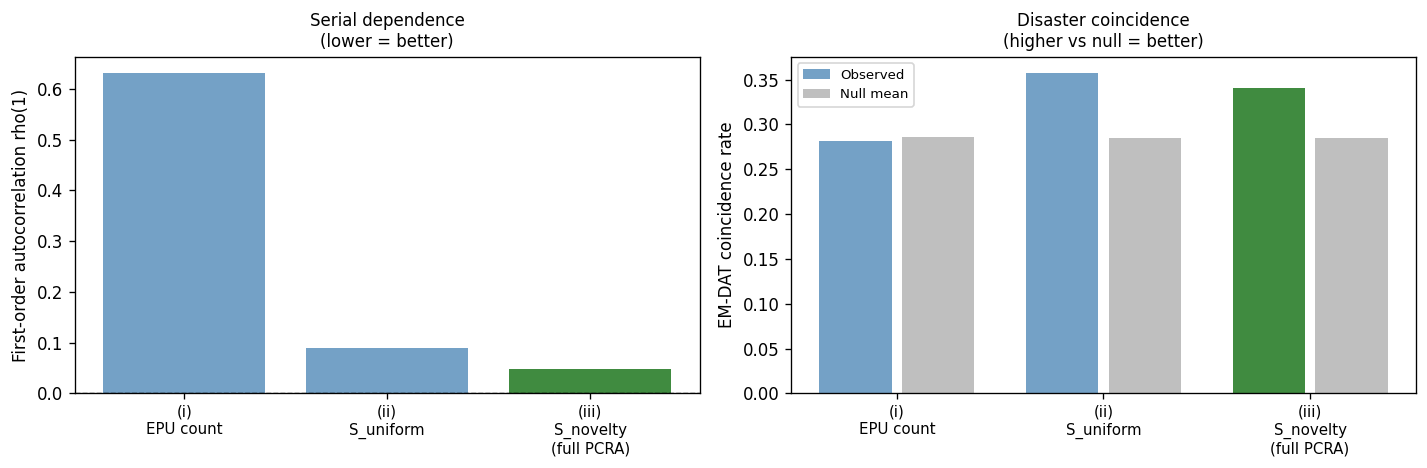


✓ Incremental construction test complete


In [23]:
# Plot: match rate vs null across three specifications 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels_short = ["(i)\nEPU count", "(ii)\nS_uniform", "(iii)\nS_novelty\n(full PCRA)"]

# Panel 1: autocorrelation
rho_vals = [autocorrs[l] for l in
            ["(i) EPU count", "(ii) S_uniform", "(iii) S_novelty (full PCRA)"]]
axes[0].bar(range(3), rho_vals, color=["steelblue", "steelblue", "darkgreen"],
            alpha=0.75)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels(labels_short, fontsize=9)
axes[0].set_ylabel("First-order autocorrelation rho(1)")
axes[0].set_title("Serial dependence\n(lower = better)", fontsize=10)
axes[0].axhline(0, color="black", linewidth=0.8, linestyle="--")

# Panel 2: EM-DAT coincidence rate vs null
obs_rates  = [coincidence_results[l]["obs_rate"]  for l in
              ["(i) EPU count", "(ii) S_uniform", "(iii) S_novelty (full PCRA)"]]
null_rates = [coincidence_results[l]["null_rate"] for l in
              ["(i) EPU count", "(ii) S_uniform", "(iii) S_novelty (full PCRA)"]]
x = range(3)
axes[1].bar([i - 0.2 for i in x], obs_rates,  width=0.35,
            color=["steelblue", "steelblue", "darkgreen"], alpha=0.75, label="Observed")
axes[1].bar([i + 0.2 for i in x], null_rates, width=0.35,
            color="grey", alpha=0.5, label="Null mean")
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(labels_short, fontsize=9)
axes[1].set_ylabel("EM-DAT coincidence rate")
axes[1].set_title("Disaster coincidence\n(higher vs null = better)", fontsize=10)
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(figdir / "incremental_construction_test.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n✓ Incremental construction test complete")

# Human Audit

## Setup

## Prerequisites

In [24]:
# Check figdir exists
try:
    figdir
    print(f"✓ figdir: {figdir}")
except NameError:
    figdir = THESIS_DATA_ROOT / "figures_extended"
    figdir.mkdir(parents=True, exist_ok=True)
    print(f"  figdir set to: {figdir}")

# Check scored_full
try:
    assert not scored_full.empty
    print(f"✓ scored_full in memory: {len(scored_full):,} rows")
except (NameError, AssertionError):
    print("  scored_full not in memory — loading from disk...")
    SCORED_PATH = THESIS_DATA_ROOT / "Phase 2" / "full_period_US_phase2_20260601_210105" / "US_full_period_phase2_scored.csv"
    scored_full = pd.read_csv(SCORED_PATH, parse_dates=["assigned_date"])
    print(f"✓ scored_full loaded: {len(scored_full):,} rows")

print(f"\nscored_full columns: {list(scored_full.columns)}")

✓ figdir: /Users/adam/Desktop/PCRA Index Thesis/Visuals/Article Level
✓ scored_full in memory: 41,920 rows

scored_full columns: ['story_id', 'country', 'score', 'n_hits', 'n_unique_terms', 'sum_contributions', 'length_norm', 'article_length', 'c_o', 'mean_severity', 'mean_intensity', 'mean_relevance', 'mean_valence', 'date', 'publish_dt_utc', 'media_name', 'title', 'url', 'beta', 'weighted_score', 'market_day', 'text_chars', 'scrape_status', 'retrieval_source', 'is_guardian_api', 'hazard_hits_n', 'hazard_terms', 'validation_country', 'validation_week_start']


## Configuration

In [25]:
import pandas as pd
import numpy as np
from pathlib import Path

SAMPLE_START  = pd.Timestamp("2014-01-01")
RANDOM_STATE  = 42
N_PASS        = 400   
N_REJECT      = 200  
TOTAL         = N_PASS + N_REJECT  

OUTPUT_DIR    = THESIS_DATA_ROOT / "Audit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_PATH   = OUTPUT_DIR / "human_coder_audit_600.csv"

print(f"✓ Config:")
print(f"  Sample start  : {SAMPLE_START.date()}")
print(f"  Pass sample   : {N_PASS} articles")
print(f"  Reject sample : {N_REJECT} articles")
print(f"  Total         : {TOTAL} articles")
print(f"  Output        : {OUTPUT_PATH}")

✓ Config:
  Sample start  : 2014-01-01
  Pass sample   : 400 articles
  Reject sample : 200 articles
  Total         : 600 articles
  Output        : /Users/adam/Desktop/PCRA Index Thesis/Validations/thesis_data/Audit/human_coder_audit_600.csv


## Build Audit Sample

## Filter-pass Sample

In [26]:
# Stratified across score quintiles to cover the full range of index values


print("Building filter-pass sample (2014+ only)...")

passed = scored_full[["story_id", "date", "score",
                       "beta", "weighted_score"]].copy()
passed["date"] = pd.to_datetime(passed["date"], errors="coerce").dt.normalize()
passed = passed[passed["date"] >= SAMPLE_START].reset_index(drop=True)

print(f"  Total passed articles (2014+) : {len(passed):,}")

# Separate zero and non-zero scores
nonzero = passed[passed["score"] > 0].copy()
zero    = passed[passed["score"] == 0].copy()
print(f"  Non-zero score : {len(nonzero):,}")
print(f"  Zero score     : {len(zero):,}")

# Quintile on non-zero scores --> 4 quintiles × 80 = 320
nonzero["score_quintile"] = pd.qcut(
    nonzero["score"], q=4, labels=False, duplicates="drop")
print(f"\n  Quintile distribution (non-zero):")
print(nonzero["score_quintile"].value_counts().sort_index().to_string())

pass_nonzero = (nonzero
    .groupby("score_quintile", group_keys=False)
    .apply(lambda g: g.sample(min(80, len(g)), random_state=RANDOM_STATE)))


pass_zero = zero.sample(min(80, len(zero)), random_state=RANDOM_STATE)
pass_zero["score_quintile"] = -1

pass_sample = pd.concat([pass_nonzero, pass_zero], ignore_index=True)
pass_sample["filter_passed"] = True

print(f"\n  Pass sample drawn : {len(pass_sample):,}")
print(pass_sample["score_quintile"].value_counts().sort_index().to_string())

Building filter-pass sample (2014+ only)...
  Total passed articles (2014+) : 38,862
  Non-zero score : 11,489
  Zero score     : 27,344

  Quintile distribution (non-zero):
score_quintile
0    2873
1    2872
2    2872
3    2872

  Pass sample drawn : 400
score_quintile
-1.000000    80


## Creating Subsample

## Filter-reject sample

In [27]:
# Load all stageA_rejects files from 2014+ 
frames      = []
files_read  = 0
files_skip  = 0

for run_dir in STAGE_A_DIRS:
    if not run_dir.exists():
        print(f"  ⚠ Folder not found — skipping: {run_dir}")
        continue

    reject_files = sorted(run_dir.glob("US_*_stageA_rejects.csv"))
    print(f"\n  {run_dir.parent.name}: {len(reject_files):,} reject files")

    for f in reject_files:
        try:
            file_date = pd.Timestamp(f.name.split("_")[1])
        except Exception:
            file_date = pd.Timestamp("2000-01-01")

        if file_date < SAMPLE_START:
            files_skip += 1
            continue

        try:
            df = pd.read_csv(f, dtype=str, low_memory=False)
            if df.empty:
                continue
            df["source_file"] = f.name
            df["source_dir"]  = run_dir.parent.name
            frames.append(df)
            files_read += 1
        except Exception as e:
            print(f"    ⚠ Could not read {f.name}: {e}")

print(f"\n  Files read (2014+) : {files_read:,}")
print(f"  Files skipped (<2014): {files_skip:,}")

if not frames:
    raise RuntimeError(
        "No reject files loaded. Check STAGE_A_DIRS paths.")

#  Combine 
all_rejects = pd.concat(frames, ignore_index=True, sort=False)
print(f"\n  Total rows before dedup : {len(all_rejects):,}")
print(f"  Columns: {list(all_rejects.columns[:10])}")

#  Standardise date column 
date_col = next(
    (c for c in ["assigned_date", "date", "publish_date", "published_at"]
     if c in all_rejects.columns), None)

if date_col is None:
    print("  ⚠ No date column found — parsing from source_file")
    all_rejects["date"] = pd.to_datetime(
        all_rejects["source_file"].str.extract(r"US_(\d{4}-\d{2}-\d{2})")[0],
        errors="coerce")
else:
    all_rejects["date"] = pd.to_datetime(
        all_rejects[date_col], errors="coerce").dt.normalize()


if "story_id" in all_rejects.columns:
    all_rejects = all_rejects.drop_duplicates(subset="story_id")
else:
    dedup_cols = [c for c in ["title", "url", "date"]
                  if c in all_rejects.columns]
    all_rejects = all_rejects.drop_duplicates(subset=dedup_cols)


all_rejects = all_rejects[
    all_rejects["date"] >= SAMPLE_START].reset_index(drop=True)

print(f"  Total rows after dedup  : {len(all_rejects):,}")
print(f"  Date range              : {all_rejects['date'].min().date()} "
      f"→ {all_rejects['date'].max().date()}")

# Sample 200 
if "source_dir" in all_rejects.columns:
    n_dirs  = all_rejects["source_dir"].nunique()
    per_dir = N_REJECT // n_dirs
    print(f"\n  Stratifying across {n_dirs} folders ({per_dir} per folder)...")
    sample_frames = []
    for src, grp in all_rejects.groupby("source_dir"):
        n = min(per_dir, len(grp))
        sample_frames.append(grp.sample(n, random_state=RANDOM_STATE))
        print(f"    {src}: {n} articles sampled from {len(grp):,}")
    sample = pd.concat(sample_frames, ignore_index=True)
    # Top up to exactly 200 if rounding left a shortfall
    if len(sample) < N_REJECT:
        remainder = all_rejects[~all_rejects.index.isin(sample.index)]
        topup     = remainder.sample(
            min(N_REJECT - len(sample), len(remainder)),
            random_state=RANDOM_STATE)
        sample = pd.concat([sample, topup], ignore_index=True)
else:
    sample = all_rejects.sample(
        min(N_REJECT, len(all_rejects)),
        random_state=RANDOM_STATE)

sample = sample.reset_index(drop=True)
print(f"\n  Final sample size : {len(sample):,}")

# Add audit columns 
sample["article_id"]     = [f"REJA_{i+1:04d}" for i in range(len(sample))]
sample["filter_passed"]  = False
sample["rejected_at"]    = "Stage A"
sample["coder_relevant"] = ""   # 1 = physical climate risk, 0 = not
sample["coder_notes"]    = ""   # free text

if "text" in sample.columns:
    sample["text_snippet"] = sample["text"].str[:500]
else:
    sample["text_snippet"] = ""

# export columns 
want_cols = [
    "article_id", "story_id", "date", "media_name",
    "title", "url", "filter_passed", "rejected_at",
    "source_dir", "coder_relevant", "coder_notes", "text_snippet",
]
export_cols = [c for c in want_cols if c in sample.columns]
missing     = [c for c in want_cols if c not in sample.columns]
if missing:
    print(f"  ⚠ Columns not available (skipped): {missing}")

coder_sheet = sample[export_cols].copy()
coder_sheet.to_csv(OUTPUT_PATH, index=False)

# Summary 
n_url = coder_sheet["url"].notna().sum() if "url" in coder_sheet.columns else 0
print(f"\n✓ Stage A reject sample exported")
print(f"  File              : {OUTPUT_PATH}")
print(f"  Rows              : {len(coder_sheet):,}")
print(f"  Articles with URL : {n_url:,} ({n_url/len(coder_sheet):.1%})")
print(f"  Date range        : {coder_sheet['date'].min().date()} "
      f"→ {coder_sheet['date'].max().date()}")

if "source_dir" in coder_sheet.columns:
    print(f"\n  Source folder distribution:")
    print(coder_sheet["source_dir"].value_counts().to_string())

if "media_name" in coder_sheet.columns:
    print(f"\n  Outlet distribution:")
    print(coder_sheet["media_name"].value_counts().to_string())

display(coder_sheet.head(10))


  Stage A: 937 reject files

  Files read (2014+) : 626
  Files skipped (<2014): 311

  Total rows before dedup : 96,263
  Columns: ['story_id', 'country', 'url', 'title', 'media_name', 'drop_reason', 'text', 'text_chars', 'retrieval_source', 'is_guardian_api']
  Total rows after dedup  : 88,405
  Date range              : 2014-01-07 → 2025-12-31

  Stratifying across 1 folders (200 per folder)...
    Stage A: 200 articles sampled from 88,405

  Final sample size : 200

✓ Stage A reject sample exported
  File              : /Users/adam/Desktop/PCRA Index Thesis/Validations/thesis_data/Audit/human_coder_audit_600.csv
  Rows              : 200
  Articles with URL : 200 (100.0%)
  Date range        : 2014-01-27 → 2025-12-31

  Source folder distribution:
source_dir
Stage A    200

  Outlet distribution:
media_name
cbsnews.com    114
cnn.com         56
nbcnews.com     16
nytimes.com     14


,article_id,story_id,date,media_name,title,url,filter_passed,rejected_at,source_dir,coder_relevant,coder_notes,text_snippet
0,REJA_0001,0caa74edfd3fa8ced13af5a9f0ea2dbf7c3e730ed2c820...,2015-12-07,cbsnews.com,"17 years after socialist revolution, power shi...",https://www.cbsnews.com/news/venezuela-opposit...,False,Stage A,Stage A,,,"17 years after socialist revolution, power shi..."
1,REJA_0002,01c28338a8e9a85ef97384d9cce3824063da2af9293ddf...,2024-09-30,cnn.com,China’s astronauts are aiming to land on the m...,https://www.cnn.com/2024/09/30/china/china-unv...,False,Stage A,Stage A,,,China has taken a step forward in its ambitiou...
2,REJA_0003,3a0cf6b81264f3a03d5d05d1103ee30113831e4ae4c148...,2025-03-04,cbsnews.com,"2 confirmed measles cases in NYC, officials say",https://www.cbsnews.com/newyork/video/2-confir...,False,Stage A,Stage A,,,Latest\nU.S.\nIran War\nJill Biden Interview\n...
3,REJA_0004,03edd6cc78992becafa982963b8e4ff929383591fa7ce4...,2025-12-17,cbsnews.com,Nick Reiner appears in court for murder of par...,https://www.cbsnews.com/miami/video/nick-reine...,False,Stage A,Stage A,,,Latest\nU.S.\nIran War\nJill Biden Interview\n...
4,REJA_0005,8fd84d763868d6a95be4fca0267971b5bc20ae0eb7c850...,2020-05-22,cnn.com,Coronavirus vaccine trial volunteers speak to CNN,https://edition.cnn.com/videos/health/2020/05/...,False,Stage A,Stage A,,,Coronavirus\n16 videos\nVideo Ad Feedback\nArt...
5,REJA_0006,8207c47fc9168aebc02b76a2ceb7163da632d328b00870...,2022-09-19,nytimes.com,Powerful Typhoon Hits Japan,https://www.nytimes.com/video/world/asia/10000...,False,Stage A,Stage A,,,new video loaded: Powerful Typhoon Hits Japan\...
6,REJA_0007,d9c7250b7ee0c95b58fc168f90b1b35f4e5b56b558ab93...,2025-07-07,nytimes.com,Blue Jackets sign restricted free agent Dmitri...,https://www.nytimes.com/athletic/6475308/2025/...,False,Stage A,Stage A,,,"COLUMBUS, Ohio — Dmitri Voronkov, who has scor..."
7,REJA_0008,84f1cdf7e8241ecb316d891246b35c2f37b0644b151b9e...,2025-09-08,cbsnews.com,Protests in Chicago as President Trump continu...,https://www.cbsnews.com/newyork/video/protests...,False,Stage A,Stage A,,,Latest\nU.S.\nIran War\nJill Biden Interview\n...
8,REJA_0009,230193f1f99518c13785517dcac638ffcf5794e77bedf7...,2015-05-07,cnn.com,Hong Kong's answer to Grumpy Cat,http://edition.cnn.com/video/data/2.0/video/tv...,False,Stage A,Stage A,,,Video Ad Feedback\nHong Kong's answer to Grump...
9,REJA_0010,6119606b6c4d8b533f386fcbf20b1faab189f9c794b78c...,2019-09-23,cbsnews.com,9/20/19: CBSN Evening News,http://feeds.cbsnews.com/~r/CBSNewsMain/~3/2qy...,False,Stage A,Stage A,,,Latest\nU.S.\nIran War\nJill Biden Interview\n...


## Merge URLs and article metadata - If necessary

In [28]:
print("Merging URLs and metadata...")

# Load stageB for URL and title of pass articles
stageB = pd.read_csv(
    SUBMISSION_ROOT / "Actual Run Data" / "Phase 1 - Articles Kept vs Rejected"
    / "Stage B" / "US_full_period_stageB_combined.csv",
    usecols=["story_id", "title", "url", "media_name", "text"],
    dtype=str
)

# Merge metadata onto pass sample
pass_with_meta = pass_sample.merge(
    stageB[["story_id", "title", "url", "media_name", "text"]],
    on="story_id", how="left")


reject_with_meta = coder_sheet.rename(columns={"text_snippet": "text"}).copy()
for col in ["score", "score_quintile", "beta", "weighted_score"]:
    reject_with_meta[col] = np.nan

reject_with_meta = reject_with_meta[[
    "story_id", "date", "score", "score_quintile",
    "filter_passed", "beta", "weighted_score",
    "title", "url", "media_name", "text"
]]

# Combine
audit_sample = pd.concat(
    [pass_with_meta, reject_with_meta],
    ignore_index=True)

# Check URL coverage
n_url = audit_sample["url"].notna().sum()
print(f"\n  Total audit articles : {len(audit_sample):,}")
print(f"  Articles with URL    : {n_url:,} ({n_url/len(audit_sample):.1%})")
print(f"  Pass articles        : {audit_sample['filter_passed'].sum():,}")
print(f"  Reject articles      : {(~audit_sample['filter_passed']).sum():,}")

Merging URLs and metadata...

  Total audit articles : 600
  Articles with URL    : 600 (100.0%)
  Pass articles        : 400
  Reject articles      : 200


# Scoring

### Direct Score

In [29]:
# Load and analyse combined scored results

import pandas as pd
from pathlib import Path

AUDIT_DIR   = SUBMISSION_ROOT / "Actual Run Data" / "Human Audit"
combined_path = AUDIT_DIR / "audit_combined_results.csv"

# Load 
df = pd.read_csv(combined_path)

print(f"Columns : {list(df.columns)}")
print(f"Rows    : {len(df):,}")
print(f"Strata  : {df['stratum'].value_counts().to_dict()}")

#  Coerce score columns to numeric (belt-and-suspenders) 
for col in ["coder_relevance", "coder_intensity", "coder_country"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

#  Split by stratum 
kept_df   = df[df["stratum"] == "pass"].copy()
reject_df = df[df["stratum"] == "reject"].copy()

print(f"\nKept (pass) rows : {len(kept_df):,}")
print(f"Reject rows      : {len(reject_df):,}")

#  Save cleaned per-stratum files 
kept_out   = AUDIT_DIR / "audit_kepts_scored.csv"
reject_out = AUDIT_DIR / "audit_rejects_scored.csv"

kept_df.to_csv(kept_out,   index=False)
reject_df.to_csv(reject_out, index=False)

print(f"\n✓ Kept file saved   : {kept_out}")
print(f"✓ Reject file saved : {reject_out}")

#  Summary statistics 
score_cols = ["coder_relevance", "coder_intensity", "coder_country"]

print("\n── Kept (pass) — coder score distributions ──")
print(kept_df[score_cols].describe().round(3).to_string())

print("\n── Rejects — coder score distributions ──")
print(reject_df[score_cols].describe().round(3).to_string())

print("\n── Relevance distribution (kept) ──")
print(kept_df["coder_relevance"].value_counts().sort_index().to_string())

print("\n── Relevance distribution (rejects) ──")
print(reject_df["coder_relevance"].value_counts().sort_index().to_string())

Columns : ['article_id', 'story_id', 'filter_passed_bin', 'coder_relevance', 'coder_intensity', 'coder_country', 'score', 'stratum']
Rows    : 600
Strata  : {'pass': 400, 'reject': 200}

Kept (pass) rows : 400
Reject rows      : 200

✓ Kept file saved   : /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Human Audit/audit_kepts_scored.csv
✓ Reject file saved : /Users/adam/Desktop/PCRA Index Thesis/Actual Run Data/Human Audit/audit_rejects_scored.csv

── Kept (pass) — coder score distributions ──
       coder_relevance  coder_intensity  coder_country
count       400.000000       400.000000     400.000000
mean          0.770000         3.708000       2.860000
std           0.421000         1.310000       0.448000
min           0.000000         1.000000       1.000000
25%           1.000000         3.000000       3.000000
50%           1.000000         4.000000       3.000000
75%           1.000000         5.000000       3.000000
max           1.000000         5.000000       3.000000


#### Compute validation statistics

In [30]:
# HUMAN CODER AUDIT — Validation metrics

import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from pathlib import Path


THRESHOLD_PRECISION = 0.85
THRESHOLD_RECALL    = 0.75
THRESHOLD_SPEARMAN  = 0.60
THRESHOLD_KAPPA     = 0.60

# Ground truth labels 
# filter_passed = True  --> PCRA relevant (positive)
# filter_passed = False --> PCRA not relevant (negative)
# coder_relevance = 1   --> relevant
# coder_relevance = 0   --> not relevant

kept_df["filter_passed_bin"]   = 1
reject_df["filter_passed_bin"] = 0

combined = pd.concat([
    kept_df[["article_id", "story_id", "filter_passed_bin",
             "coder_relevance", "coder_intensity",
             "coder_country", "score", "stratum"]],
    reject_df[["article_id", "story_id", "filter_passed_bin",
               "coder_relevance", "coder_intensity",
               "coder_country", "stratum"]],
], ignore_index=True)

combined = combined.dropna(subset=["coder_relevance", "filter_passed_bin"])
combined["coder_relevance"]    = combined["coder_relevance"].astype(int)
combined["filter_passed_bin"]  = combined["filter_passed_bin"].astype(int)

y_true = combined["filter_passed_bin"].values   
y_pred = combined["coder_relevance"].values      

print(f"Combined sample : {len(combined):,} articles")
print(f"  Pass (PCRA=1) : {combined['filter_passed_bin'].sum():,}")
print(f"  Reject (PCRA=0): {(combined['filter_passed_bin']==0).sum():,}")
print(f"  Coder relevant : {combined['coder_relevance'].sum():,}")
print(f"  Coder not relevant: {(combined['coder_relevance']==0).sum():,}")


Combined sample : 600 articles
  Pass (PCRA=1) : 400
  Reject (PCRA=0): 200
  Coder relevant : 344
  Coder not relevant: 256


In [31]:

#  Confusion matrix 
cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()

print(f"\n── Confusion matrix ──")
print(f"  True positives  (PCRA=1, coder=1) : {tp}")
print(f"  False positives (PCRA=0, coder=1) : {fp}")
print(f"  True negatives  (PCRA=0, coder=0) : {tn}")
print(f"  False negatives (PCRA=1, coder=0) : {fn}")



── Confusion matrix ──
  True positives  (PCRA=1, coder=1) : 308
  False positives (PCRA=0, coder=1) : 36
  True negatives  (PCRA=0, coder=0) : 164
  False negatives (PCRA=1, coder=0) : 92


In [32]:

#  Precision and recall 
precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
recall    = tp / (tp + fn) if (tp + fn) > 0 else np.nan
f1        = (2 * precision * recall / (precision + recall)
             if (precision + recall) > 0 else np.nan)

print(f"\n── Precision and recall ──")
print(f"  Precision : {precision:.4f}  "
      f"(threshold ≥ {THRESHOLD_PRECISION}) "
      f"{'✓ PASS' if precision >= THRESHOLD_PRECISION else '✗ FAIL'}")
print(f"  Recall    : {recall:.4f}  "
      f"(threshold ≥ {THRESHOLD_RECALL}) "
      f"{'✓ PASS' if recall >= THRESHOLD_RECALL else '✗ FAIL'}")
print(f"  F1 score  : {f1:.4f}")



── Precision and recall ──
  Precision : 0.8953  (threshold ≥ 0.85) ✓ PASS
  Recall    : 0.7700  (threshold ≥ 0.75) ✓ PASS
  F1 score  : 0.8280


In [33]:
# Spearman correlation —-> PCRA score vs coder intensity 

kept_valid = kept_df.dropna(subset=["score", "coder_intensity"])
rho, p_rho = spearmanr(kept_valid["score"], kept_valid["coder_intensity"])

print(f"\n── Spearman ρ: PCRA score vs coder intensity (pass articles) ──")
print(f"  ρ = {rho:.4f}  p = {p_rho:.4f}  n = {len(kept_valid):,}")
print(f"  Threshold ≥ {THRESHOLD_SPEARMAN}: "
      f"{'✓ PASS' if rho >= THRESHOLD_SPEARMAN else '✗ FAIL'}")



── Spearman ρ: PCRA score vs coder intensity (pass articles) ──
  ρ = 0.2810  p = 0.0000  n = 400
  Threshold ≥ 0.6: ✗ FAIL


In [34]:
#  Cohen's k
kappa = cohen_kappa_score(y_true, y_pred)
print(f"\n── Cohen's κ ──")
print(f"  κ = {kappa:.4f}  "
      f"(threshold ≥ {THRESHOLD_KAPPA}) "
      f"{'✓ PASS' if kappa >= THRESHOLD_KAPPA else '✗ FAIL'}")



── Cohen's κ ──
  κ = 0.5514  (threshold ≥ 0.6) ✗ FAIL


In [35]:
accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else np.nan

print(f"  Accuracy  : {accuracy:.4f}  "
      f"(tp={tp}, tn={tn}, fp={fp}, fn={fn}, n={tp+tn+fp+fn})")

  Accuracy  : 0.7867  (tp=308, tn=164, fp=36, fn=92, n=600)


In [36]:
# Summary table 
summary = pd.DataFrame([
    {"metric":    "Precision",
     "value":     round(precision, 4),
     "threshold": THRESHOLD_PRECISION,
     "pass":      precision >= THRESHOLD_PRECISION},
    {"metric":    "Recall",
     "value":     round(recall, 4),
     "threshold": THRESHOLD_RECALL,
     "pass":      recall >= THRESHOLD_RECALL},
    {"metric":    "Spearman ρ (score vs intensity)",
     "value":     round(rho, 4),
     "threshold": THRESHOLD_SPEARMAN,
     "pass":      rho >= THRESHOLD_SPEARMAN},
    {"metric":    "Cohen's κ",
     "value":     round(kappa, 4),
     "threshold": THRESHOLD_KAPPA,
     "pass":      kappa >= THRESHOLD_KAPPA},
    {"metric":    "Accuracy",
     "value":     round(accuracy, 4),
     "threshold": None,
     "pass":      None},
    {"metric":    "F1 score",
     "value":     round(f1, 4) if not np.isnan(f1) else np.nan,
     "threshold": None,
     "pass":      None},
])

print(f"\n── Validation summary ──")
display(summary)

valid_pass = summary["pass"].dropna()
all_pass   = valid_pass.all()
print(f"\nOverall: {'✓ All thresholds met — human-coder audit PASSES' if all_pass else '✗ One or more thresholds not met — review individual metrics'}")



── Validation summary ──


,metric,value,threshold,pass
0,Precision,0.895300,0.850000,True
1,Recall,0.770000,0.750000,True
2,Spearman ρ (score vs intensity),0.281000,0.600000,False
3,Cohen's κ,0.551400,0.600000,False
4,Accuracy,0.786700,NaN,None
5,F1 score,0.828000,NaN,None



Overall: ✗ One or more thresholds not met — review individual metrics


In [37]:

# stratum breakdown 
print(f"\n── Relevance agreement by stratum ──")
print(combined.groupby("stratum")[["filter_passed_bin", "coder_relevance"]]
      .mean().round(3).to_string())



── Relevance agreement by stratum ──
         filter_passed_bin  coder_relevance
stratum                                    
pass              1.000000         0.770000
reject            0.000000         0.180000


In [38]:

# combined audit results 
AUDIT_DIR    = THESIS_DATA_ROOT / "Audit"
combined_out = AUDIT_DIR / "audit_combined_results.csv"
combined.to_csv(combined_out, index=False)
print(f"\n✓ Combined results saved: {combined_out}")


✓ Combined results saved: /Users/adam/Desktop/PCRA Index Thesis/Validations/thesis_data/Audit/audit_combined_results.csv


In [39]:
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import pandas as pd

print(combined['coder_relevance'].value_counts(dropna=False))
print(combined['filter_passed_bin'].value_counts(dropna=False))
print(combined['stratum'].value_counts(dropna=False))

coder_relevance
1    344
0    256
Name: count, dtype: int64
filter_passed_bin
1    400
0    200
Name: count, dtype: int64
stratum
pass      400
reject    200
Name: count, dtype: int64


In [40]:
from sklearn.metrics import confusion_matrix, cohen_kappa_score

y_human = combined['coder_relevance']
y_model = combined['filter_passed_bin']

labels = [0, 1]  

cm = confusion_matrix(y_human, y_model, labels=labels)
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix (rows=human coder_relevance, cols=classifier filter_passed_bin):")
print(pd.DataFrame(cm, index=[f"human_{l}" for l in labels],
                        columns=[f"model_{l}" for l in labels]))
print(f"\ntp={tp}, fp={fp}, fn={fn}, tn={tn}")
assert tp + fp + fn + tn == 600, "Expected the full 400/200 audit sample"

def pabak_from_confusion(tp, fp, fn, tn, label="physical-only rule"):
    n = tp + fp + fn + tn
    po = (tp + tn) / n
    pabak = 2 * po - 1
    print(f"--- PABAK: {label} ---")
    print(f"N                     = {n}")
    print(f"Observed agreement po = {po:.4f}")
    print(f"PABAK                 = {pabak:.4f}")
    return pabak

pabak = pabak_from_confusion(tp, fp, fn, tn)

kappa = cohen_kappa_score(y_human, y_model)
print(f"\nCohen's kappa = {kappa:.3f}")
print(f"PABAK         = {pabak:.3f}")
print(f"Delta (PABAK - kappa) = {pabak - kappa:.3f}")

Confusion matrix (rows=human coder_relevance, cols=classifier filter_passed_bin):
         model_0  model_1
human_0      164       92
human_1       36      308

tp=308, fp=92, fn=36, tn=164
--- PABAK: physical-only rule ---
N                     = 600
Observed agreement po = 0.7867
PABAK                 = 0.5733

Cohen's kappa = 0.551
PABAK         = 0.573
Delta (PABAK - kappa) = 0.022


### Combinations

In [41]:
# HUMAN CODER AUDIT — Combination summary


import pandas as pd

# Kept articles 
print("── Kept (pass) articles — combination counts ──\n")
kept_combos = (kept_df
    .groupby(["coder_relevance", "coder_intensity", "coder_country"],
             dropna=False)
    .size()
    .reset_index(name="count")
    .sort_values(["coder_relevance", "coder_country", "coder_intensity"],
                 ascending=[False, False, False])
    .reset_index(drop=True))

kept_combos["pct"] = (kept_combos["count"] / len(kept_df) * 100).round(1)
display(kept_combos)

print(f"\nTotal kept articles : {len(kept_df):,}")
print(f"Unique combinations : {len(kept_combos):,}")

# Reject articles 
print("\n── Reject articles — combination counts ──\n")
reject_combos = (reject_df
    .groupby(["coder_relevance", "coder_intensity", "coder_country"],
             dropna=False)
    .size()
    .reset_index(name="count")
    .sort_values(["coder_relevance", "coder_country", "coder_intensity"],
                 ascending=[False, False, False])
    .reset_index(drop=True))

reject_combos["pct"] = (reject_combos["count"] / len(reject_df) * 100).round(1)
display(reject_combos)

print(f"\nTotal reject articles : {len(reject_df):,}")
print(f"Unique combinations   : {len(reject_combos):,}")

#  Pairwise: relevance × country
print("\n── Kept: relevance × country (collapsed across intensity) ──")
display(kept_df.groupby(["coder_relevance", "coder_country"], dropna=False)
        .size().unstack(fill_value=0))

print("\n── Rejects: relevance × country (collapsed across intensity) ──")
display(reject_df.groupby(["coder_relevance", "coder_country"], dropna=False)
        .size().unstack(fill_value=0))

#  Relevance × intensity 
print("\n── Kept: relevance × intensity (collapsed across country) ──")
display(kept_df.groupby(["coder_relevance", "coder_intensity"], dropna=False)
        .size().unstack(fill_value=0))

print("\n── Rejects: relevance × intensity (collapsed across country) ──")
display(reject_df.groupby(["coder_relevance", "coder_intensity"], dropna=False)
        .size().unstack(fill_value=0))

── Kept (pass) articles — combination counts ──



,coder_relevance,coder_intensity,coder_country,count,pct
0,1,5,3,129,32.200000
1,1,4,3,114,28.500000
2,1,3,3,35,8.800000
3,1,2,3,5,1.200000
4,1,1,3,1,0.200000
5,1,5,2,9,2.200000
6,1,4,2,4,1.000000
7,1,3,2,4,1.000000
8,1,2,2,1,0.200000
9,1,5,1,5,1.200000



Total kept articles : 400
Unique combinations : 20

── Reject articles — combination counts ──



,coder_relevance,coder_intensity,coder_country,count,pct
0,1,5,3,1,0.500000
1,1,4,3,7,3.500000
2,1,3,3,5,2.500000
3,1,2,3,3,1.500000
4,1,4,1,10,5.000000
5,1,3,1,5,2.500000
6,1,2,1,5,2.500000
7,0,5,3,1,0.500000
8,0,4,3,10,5.000000
9,0,3,3,39,19.500000



Total reject articles : 200
Unique combinations   : 22

── Kept: relevance × country (collapsed across intensity) ──


coder_country,1,2,3
coder_relevance,,,
0,10,6,76
1,6,18,284


... (2 outputs left out)


── Kept: relevance × intensity (collapsed across country) ──


coder_intensity,1,2,3,4,5
coder_relevance,,,,,
0,35,44,13,0,0
1,1,6,39,119,143



── Rejects: relevance × intensity (collapsed across country) ──


coder_intensity,0,1,2,3,4,5
coder_relevance,,,,,,
0,3,7,70,66,17,1
1,0,0,8,10,17,1


#### Scoring Combos

In [42]:
# HUMAN CODER AUDIT — Validation metrics
# Pass articles   : coder_relevance=1 AND coder_country ∈ {2,3} --> true positive
# Reject articles : coder_relevance=1 AND coder_country=3        --> false negative



# Label each article 

def classify_article(row):
    '''
    Returns classification based on PCRA decision and coder scores.

    Pass articles (filter_passed=1):
        coder_relevance=1 AND coder_country in {2,3} → True Positive
        otherwise                                     → False Positive

    Reject articles (filter_passed=0):
        coder_relevance=1 AND coder_country=3         → False Negative
        otherwise                                     → True Negative
    '''
    rel     = row["coder_relevance"]
    country = row["coder_country"]
    passed  = row["filter_passed_bin"]

    if passed == 1:
        if rel == 1 and country in [2, 3]:
            return "TP"
        else:
            return "FP"
    else:
        if rel == 1 and country == 3:
            return "FN"
        else:
            return "TN"

combined["classification"] = combined.apply(classify_article, axis=1)

print("── Classification distribution ──")
print(combined["classification"].value_counts().to_string())
print()
print(combined.groupby(["stratum", "classification"])
      .size().unstack(fill_value=0).to_string())


── Classification distribution ──
classification
TP    302
TN    184
FP     98
FN     16

classification  FN  FP   TN   TP
stratum                         
pass             0  98    0  302
reject          16   0  184    0


In [43]:
#  Extract TP FP TN FN counts 
counts = combined["classification"].value_counts()
tp = int(counts.get("TP", 0))
fp = int(counts.get("FP", 0))
tn = int(counts.get("TN", 0))
fn = int(counts.get("FN", 0))

print(f"\n── Confusion matrix ──")
print(f"  True positives  (PCRA passed,   coder relevant+US)     : {tp}")
print(f"  False positives (PCRA passed,   coder not relevant/US) : {fp}")
print(f"  True negatives  (PCRA rejected, coder not relevant/US) : {tn}")
print(f"  False negatives (PCRA rejected, coder relevant+US=3)   : {fn}")




── Confusion matrix ──
  True positives  (PCRA passed,   coder relevant+US)     : 302
  False positives (PCRA passed,   coder not relevant/US) : 98
  True negatives  (PCRA rejected, coder not relevant/US) : 184
  False negatives (PCRA rejected, coder relevant+US=3)   : 16


In [44]:
# Precision and recall 
precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
recall    = tp / (tp + fn) if (tp + fn) > 0 else np.nan
f1        = (2 * precision * recall / (precision + recall)
             if not np.isnan(precision) and not np.isnan(recall)
             and (precision + recall) > 0 else np.nan)

print(f"\n── Precision and recall ──")
print(f"  Precision : {precision:.4f}  "
      f"(threshold ≥ {THRESHOLD_PRECISION})  "
      f"{'✓ PASS' if precision >= THRESHOLD_PRECISION else '✗ FAIL'}")
print(f"  Recall    : {recall:.4f}  "
      f"(threshold ≥ {THRESHOLD_RECALL})  "
      f"{'✓ PASS' if recall >= THRESHOLD_RECALL else '✗ FAIL'}")
print(f"  F1 score  : {f1:.4f}" if not np.isnan(f1) else "  F1 score  : N/A")



── Precision and recall ──
  Precision : 0.7550  (threshold ≥ 0.85)  ✗ FAIL
  Recall    : 0.9497  (threshold ≥ 0.75)  ✓ PASS
  F1 score  : 0.8412


In [45]:
# Cohen's k
# PCRA positive = passed, coder positive = TP or FN (coder says relevant+US)
combined["pcra_label"]  = combined["filter_passed_bin"]
combined["coder_label"] = combined["classification"].map(
    {"TP": 1, "FP": 0, "TN": 0, "FN": 1})

kappa_valid = combined.dropna(subset=["pcra_label", "coder_label"])
if kappa_valid["pcra_label"].nunique() > 1 and kappa_valid["coder_label"].nunique() > 1:
    kappa = cohen_kappa_score(
        kappa_valid["pcra_label"].astype(int),
        kappa_valid["coder_label"].astype(int))
    print(f"\n── Cohen's κ ──")
    print(f"  κ = {kappa:.4f}  "
          f"(threshold ≥ {THRESHOLD_KAPPA})  "
          f"{'✓ PASS' if kappa >= THRESHOLD_KAPPA else '✗ FAIL'}")
else:
    kappa = np.nan
    print("\n── Cohen's κ : N/A (single class) ──")



── Cohen's κ ──
  κ = 0.6122  (threshold ≥ 0.6)  ✓ PASS


In [46]:

#  Spearman ρ —  vs coder intensity 
tp_articles = combined[combined["classification"] == "TP"].dropna(
    subset=["score", "coder_intensity"])

if len(tp_articles) >= 10:
    rho, p_rho = spearmanr(tp_articles["score"], tp_articles["coder_intensity"])
    print(f"\n── Spearman ρ: PCRA score vs coder intensity (TP articles only) ──")
    print(f"  ρ = {rho:.4f}  p = {p_rho:.4f}  n = {len(tp_articles):,}")
    print(f"  Threshold ≥ {THRESHOLD_SPEARMAN}: "
          f"{'✓ PASS' if rho >= THRESHOLD_SPEARMAN else '✗ FAIL'}")
else:
    rho, p_rho = np.nan, np.nan
    print(f"\n  ⚠ Insufficient TP articles for Spearman ρ (n={len(tp_articles)})")



── Spearman ρ: PCRA score vs coder intensity (TP articles only) ──
  ρ = 0.1942  p = 0.0007  n = 302
  Threshold ≥ 0.6: ✗ FAIL


In [47]:
#  Accuracy 
accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else np.nan

print(f"  Accuracy  : {accuracy:.4f}  "
      f"(tp={tp}, tn={tn}, fp={fp}, fn={fn}, n={tp+tn+fp+fn})")

  Accuracy  : 0.8100  (tp=302, tn=184, fp=98, fn=16, n=600)


In [48]:
#  Summary table 
summary_rows = [
    {"metric":    "Precision",
     "value":     round(precision, 4),
     "threshold": THRESHOLD_PRECISION,
     "pass":      bool(precision >= THRESHOLD_PRECISION)},
    {"metric":    "Recall",
     "value":     round(recall, 4),
     "threshold": THRESHOLD_RECALL,
     "pass":      bool(recall >= THRESHOLD_RECALL)},
    {"metric":    "Accuracy",
     "value":     round(accuracy, 4),
     "threshold": None,
     "pass":      None},
    {"metric":    "F1 score",
     "value":     round(f1, 4) if not np.isnan(f1) else np.nan,
     "threshold": None,
     "pass":      None},
]

summary_final = pd.DataFrame(summary_rows)
print(f"\n── Final validation summary ──")
print(f"  Classification rules:")
print(f"    TP : PCRA passed,   coder_relevance=1, coder_country ∈ {{2,3}}")
print(f"    FP : PCRA passed,   coder does not meet TP criteria")
print(f"    FN : PCRA rejected, coder_relevance=1, coder_country=3")
print(f"    TN : PCRA rejected, coder does not meet FN criteria")
display(summary_final)

all_pass = summary_final["pass"].all()
print(f"\nOverall: "
      f"{'✓ All thresholds met — human-coder audit PASSES' if all_pass else '✗ One or more thresholds not met — review individual metrics'}")



── Final validation summary ──
  Classification rules:
    TP : PCRA passed,   coder_relevance=1, coder_country ∈ {2,3}
    FP : PCRA passed,   coder does not meet TP criteria
    FN : PCRA rejected, coder_relevance=1, coder_country=3
    TN : PCRA rejected, coder does not meet FN criteria


,metric,value,threshold,pass
0,Precision,0.755000,0.850000,False
1,Recall,0.949700,0.750000,True
2,Accuracy,0.810000,NaN,None
3,F1 score,0.841200,NaN,None



Overall: ✗ One or more thresholds not met — review individual metrics


## Spearman Range

In [49]:
from scipy.stats import spearmanr

#  Option one: Spearman on full 600-article sample 
df_full = df.copy()  # all 600 articles

# Human intensity: coder_intensity where relevant, 0 where coder marked not relevant
df_full['human_intensity_full'] = df_full.apply(
    lambda r: r['coder_intensity'] if r['coder_relevance'] == 1 else 0,
    axis=1
)

rho_full, p_full = spearmanr(
    df_full['score'],
    df_full['human_intensity_full']
)

#  True-positive subset for comparison 
df_tp = df_full[df_full['coder_relevance'] == 1]
rho_tp, p_tp = spearmanr(df_tp['score'], df_tp['coder_intensity'])

#  Score distribution comparison 
print("Score range among true positives:")
print(df_tp['score'].describe())
print("\nScore range across full 600-article sample:")
print(df_full['score'].describe())

print(f"\nSpearman ρ — true positives only (n={len(df_tp)}): {rho_tp:.3f}, p={p_tp:.3f}")
print(f"Spearman ρ — full sample (n={len(df_full)}):        {rho_full:.3f}, p={p_full:.3f}")

print("\nInterpretation:")
if rho_full > rho_tp + 0.10:
    print("Range restriction confirmed: correlation rises substantially on full sample.")
elif rho_full > rho_tp:
    print("Modest attenuation from range restriction, but effect is small.")
else:
    print("Range restriction does not explain the low correlation.")

Score range among true positives:
count   308.000000
mean      0.013029
std       0.022771
min       0.000000
25%       0.000558
50%       0.004916
75%       0.014113
max       0.180948
Name: score, dtype: float64

Score range across full 600-article sample:
count   400.000000
mean      0.011225
std       0.021284
min       0.000000
25%       0.000249
50%       0.002170
75%       0.012712
max       0.180948
Name: score, dtype: float64

Spearman ρ — true positives only (n=344): nan, p=nan
Spearman ρ — full sample (n=600):        nan, p=nan

Interpretation:
Range restriction does not explain the low correlation.


In [50]:
df_tp = df[df['coder_relevance'] == 1].dropna(subset=['score'])
rho_tp, p_tp = spearmanr(df_tp['score'], df_tp['coder_intensity'])

df_kept = df.dropna(subset=['score'])  # all 400 retained articles
df_kept['human_intensity_full'] = df_kept.apply(
    lambda r: r['coder_intensity'] if r['coder_relevance'] == 1 else 0,
    axis=1
)
rho_full, p_full = spearmanr(df_kept['score'], df_kept['human_intensity_full'])

print(f"Spearman ρ — true positives only (n={len(df_tp)}): {rho_tp:.3f}, p={p_tp:.3f}")
print(f"Spearman ρ — kept articles full (n={len(df_kept)}): {rho_full:.3f}, p={p_full:.3f}")

Spearman ρ — true positives only (n=308): 0.197, p=0.000
Spearman ρ — kept articles full (n=400): 0.284, p=0.000
